# 02 · Modelo Digital de Elevación (DEM)
**Dato tipo SUPERFICIE:** Copernicus GLO-30 (30 m), descargado del bucket público de AWS, sin registro.

**¿Para qué sirve en este trabajo?**
1. **Irradiancia de cielo despejado:** el modelo Ineichen usa la altitud. El Magdalena va de 0 m a ~5.700 m en la Sierra Nevada de Santa Marta.
2. **Relieve y convección:** permite relacionar la frecuencia de SCM con la altitud (notebook 08).
3. **Pendiente:** indica dónde hay terreno apto para nuevos parques (< ~10°).

**Productos:**
- `dem_region_30m.tif`
- `pendiente_grados.tif`
- `orientacion_grados.tif`
- `dem_2km.tif`, el DEM promediado a la malla de análisis.

In [1]:
# ▶ CELDA DE PREPARACIÓN — ejecútala siempre de primera
import os, sys, subprocess
from pathlib import Path

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB:
    # En Colab los archivos se guardan en tu Google Drive para no perderlos
    from google.colab import drive
    drive.mount("/content/drive")
    CARPETA = Path("/content/drive/MyDrive/scm_magdalena")   # cámbiala si quieres
    CARPETA.mkdir(parents=True, exist_ok=True)
    os.chdir(CARPETA)
    PAQUETES = ["numpy", "scipy", "pandas", "xarray", "dask", "netCDF4", "h5netcdf", "s3fs", "pyproj", "shapely", "geopandas", "rasterio", "pvlib", "pydataxm", "libpysal", "esda", "matplotlib"]
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *PAQUETES], check=True)

if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("Carpeta de trabajo:", os.getcwd())
assert Path("config.py").exists(), "No encuentro config.py: ejecuta primero el notebook 00 en esta misma carpeta"

Carpeta de trabajo: c:\Users\User\Desktop\Unal\Analisis Geoespacial\notebooks_scm_magdalena


In [2]:
import numpy as np
import rasterio
from rasterio.merge import merge
from rasterio.mask import mask
from rasterio.warp import reproject, Resampling, calculate_default_transform
from rasterio.transform import from_origin
import geopandas as gpd
import matplotlib.pyplot as plt
import config as C

URL = ("https://copernicus-dem-30m.s3.amazonaws.com/"
       "Copernicus_DSM_COG_10_{ns}{lat:02d}_00_{ew}{lon:03d}_00_DEM/"
       "Copernicus_DSM_COG_10_{ns}{lat:02d}_00_{ew}{lon:03d}_00_DEM.tif")

## 1. Descargar y unir las teselas de 1° × 1°

In [3]:
la0, la1, lo0, lo1 = C.DOM_ANALISIS
fuentes = []
for lat in range(int(np.floor(la0)), int(np.ceil(la1))):
    for lon in range(int(np.floor(lo0)), int(np.ceil(lo1))):
        u = URL.format(ns="N" if lat >= 0 else "S", lat=abs(lat), ew="W" if lon < 0 else "E", lon=abs(lon))
        try:
            fuentes.append(rasterio.open(u)); print("ok        ", u.split("/")[-1])
        except Exception:
            print("sin tesela", u.split("/")[-1], "(mar)")

mosaico, transf = merge(fuentes)
perfil = fuentes[0].profile | {"height": mosaico.shape[1], "width": mosaico.shape[2], "transform": transf,
                               "driver": "GTiff", "compress": "lzw", "tiled": True, "nodata": -9999}
tmp = C.RAW / "dem_mosaico.tif"
with rasterio.open(tmp, "w", **perfil) as dst:
    dst.write(mosaico)
print("Mosaico:", mosaico.shape)

ok         Copernicus_DSM_COG_10_N08_00_W076_00_DEM.tif
ok         Copernicus_DSM_COG_10_N08_00_W075_00_DEM.tif
ok         Copernicus_DSM_COG_10_N08_00_W074_00_DEM.tif
ok         Copernicus_DSM_COG_10_N09_00_W076_00_DEM.tif
ok         Copernicus_DSM_COG_10_N09_00_W075_00_DEM.tif
ok         Copernicus_DSM_COG_10_N09_00_W074_00_DEM.tif
ok         Copernicus_DSM_COG_10_N10_00_W076_00_DEM.tif
ok         Copernicus_DSM_COG_10_N10_00_W075_00_DEM.tif
ok         Copernicus_DSM_COG_10_N10_00_W074_00_DEM.tif
sin tesela Copernicus_DSM_COG_10_N11_00_W076_00_DEM.tif (mar)
ok         Copernicus_DSM_COG_10_N11_00_W075_00_DEM.tif
ok         Copernicus_DSM_COG_10_N11_00_W074_00_DEM.tif
Mosaico: (1, 14400, 10800)


## 2. Recortar al departamento

In [4]:
region = gpd.read_file(C.PROC / "region.gpkg").to_crs(4326)
with rasterio.open(tmp) as src:
    rec, t2 = mask(src, region.geometry.buffer(0.05), crop=True, nodata=-9999)
    perfil.update(height=rec.shape[1], width=rec.shape[2], transform=t2)
with rasterio.open(C.PROC / "dem_region_30m.tif", "w", **perfil) as dst:
    dst.write(rec)
z30 = np.where(rec[0] == -9999, np.nan, rec[0])
print(f"Altitud: mín {np.nanmin(z30):.0f} m · máx {np.nanmax(z30):.0f} m")

C:\Users\User\AppData\Local\Temp\ipykernel_24224\3891952587.py:3: UserWarning: Geometry is in a geographic CRS. Results from 'buffer' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  rec, t2 = mask(src, region.geometry.buffer(0.05), crop=True, nodata=-9999)


Altitud: mín -9 m · máx 5698 m


## 3. Pendiente y orientación (en MAGNA-SIRGAS Origen Nacional, EPSG:9377, en metros)

In [5]:
with rasterio.open(C.PROC / "dem_region_30m.tif") as src:
    dst_crs = "EPSG:9377"
    t, w, h = calculate_default_transform(src.crs, dst_crs, src.width, src.height, *src.bounds, resolution=30)
    z = np.full((h, w), np.nan, dtype="float32")
    reproject(rasterio.band(src, 1), z, dst_transform=t, dst_crs=dst_crs,
              resampling=Resampling.bilinear, src_nodata=-9999, dst_nodata=np.nan)
gy, gx = np.gradient(z, 30.0)
pendiente = np.degrees(np.arctan(np.hypot(gx, gy)))
orientacion = (np.degrees(np.arctan2(-gx, gy)) + 360) % 360
pm = {"driver": "GTiff", "height": h, "width": w, "count": 1, "dtype": "float32",
      "crs": dst_crs, "transform": t, "nodata": np.nan, "compress": "lzw"}
for nombre, arr in (("pendiente_grados", pendiente), ("orientacion_grados", orientacion)):
    with rasterio.open(C.PROC / f"{nombre}.tif", "w", **pm) as dst:
        dst.write(arr.astype("float32"), 1)
print(f"Área con pendiente < 10° (apta para parques): {100*np.nanmean(pendiente < 10):.1f} %")

Área con pendiente < 10° (apta para parques): 47.2 %


## 4. DEM promedio en la malla de análisis (~2 km)

In [6]:
res = C.RES_MALLA
ny, nx = int(round((la1 - la0) / res)), int(round((lo1 - lo0) / res))
t2km = from_origin(lo0, la1, res, res)
z2 = np.full((ny, nx), np.nan, dtype="float32")
with rasterio.open(tmp) as src:
    reproject(rasterio.band(src, 1), z2, dst_transform=t2km, dst_crs="EPSG:4326",
              resampling=Resampling.average, src_nodata=-9999, dst_nodata=np.nan)
with rasterio.open(C.PROC / "dem_2km.tif", "w", driver="GTiff", height=ny, width=nx, count=1,
                   dtype="float32", crs="EPSG:4326", transform=t2km, nodata=np.nan) as dst:
    dst.write(z2, 1)
print("dem_2km.tif:", z2.shape)

dem_2km.tif: (150, 90)


## 5. Mapas de control

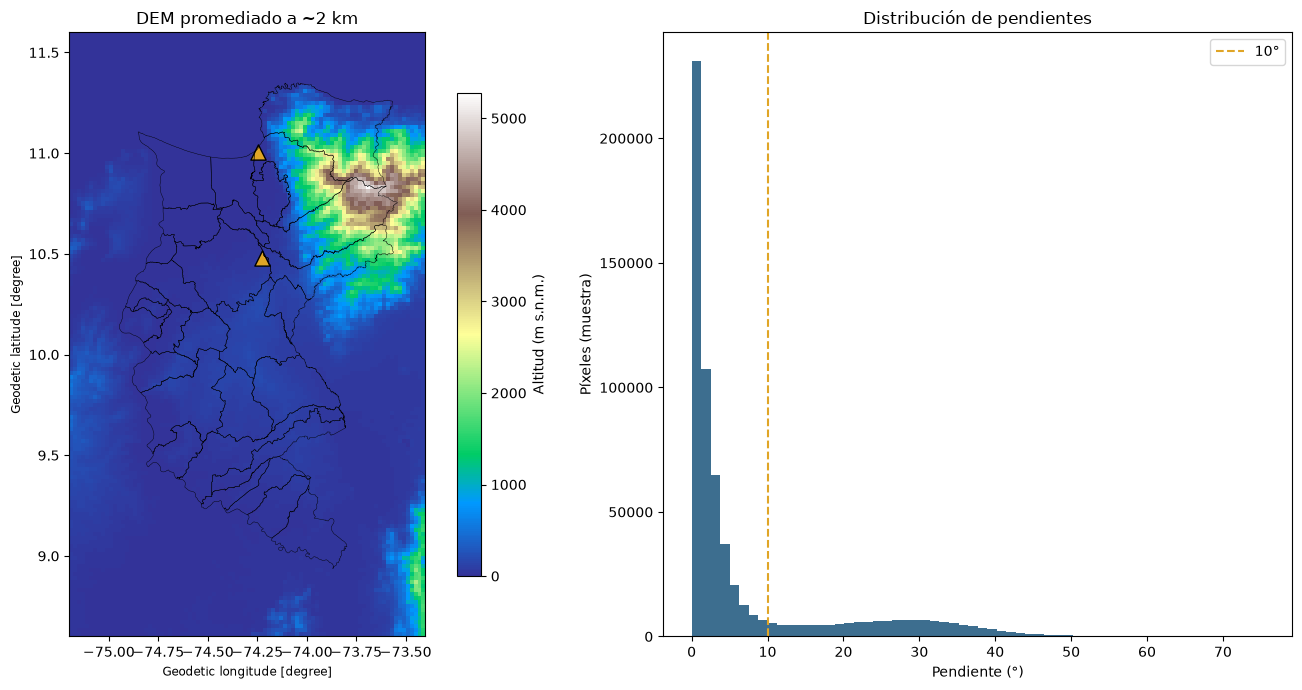

In [7]:
parques = gpd.read_file(C.PROC / "parques.gpkg")
mpios = gpd.read_file(C.PROC / "municipios.gpkg")
fig, axs = plt.subplots(1, 2, figsize=(14, 7))
ext = [lo0, lo1, la0, la1]
im = axs[0].imshow(z2, extent=ext, cmap="terrain", vmin=0)
plt.colorbar(im, ax=axs[0], label="Altitud (m s.n.m.)", shrink=0.8)
axs[0].set_title("DEM promediado a ~2 km")
axs[1].hist(pendiente[np.isfinite(pendiente)].ravel()[::50], bins=60, color="#3D6E8F")
axs[1].axvline(10, color="#E0A526", ls="--", label="10°")
axs[1].set_xlabel("Pendiente (°)"); axs[1].set_ylabel("Píxeles (muestra)"); axs[1].legend()
axs[1].set_title("Distribución de pendientes")
mpios.boundary.plot(ax=axs[0], color="k", linewidth=0.3)
parques.plot(ax=axs[0], color="#E0A526", edgecolor="k", marker="^", markersize=120)
plt.tight_layout(); plt.savefig(C.OUT / "mapa_dem.png", dpi=150); plt.show()

✅ Sigue con el notebook **03** (la descarga de GOES es la parte más larga).